# Isaac Sim on a DGX Spark

## Prerequisites

In [1]:
# HIDE/SHOW
# ! pip install -U numpy
# ! pip install -U matplotlib

## Visualization in Python

The folder of this notebook holds a small module, `simscene`, with the scenes of this course, the charts and diagrams, and what draws them. It needs NumPy and matplotlib only: every picture on this page is drawn by the notebook, not by Isaac Sim. The 3D scenes are lit the way a 3D program lights a studio shot: one lamp with soft shadows, light from the sky and from the floor, and pastel colours. Regular text in the figures is set in NVIDIA Sans, mathematics in the typeface of LaTeX, and names taken from code in Consolas; a typeface that a computer does not have is replaced by a similar one.

In [2]:
# HIDE/SHOW
import warnings
warnings.filterwarnings('ignore')

from simscene import colour

colour('chapter0.ipynb')           # the code blocks of this page in the colours Notion gives them

<42 pieces of code in colour>

## Utilizations

The module is built from four small class families. Each has methods that its subclasses override, so that one call draws any member.

| | Base class | Subclasses | Overridden |
|---|---|---|---|
| **Picture** | `Picture` | `Scene`, `Chart` | `bundle()`: what the cell displays |
| **Scene** | `Scene` | `HelloCube`, `FallingCube` | `shapes()`: the triangle meshes of the scene; `motion()`: what moves with time |
| **Chart** | `Chart` | `FallChart`, `Diagram`, `SetupDiagram` | `plot(fig)`: the still picture; `items(sheet)`: the items of the interactive figure |
| **Renderer** | `Renderer` | `Still`, `Canvas`, `Plot`, `Stage` | `draw(picture)`: a still picture, a 3D canvas, a Plotly figure, or prims on a USD stage |

A scene is a list of shapes and a camera. Both come from `labs/scene.py`, the file that the lab scripts read on the DGX Spark, so this page and the simulator are given the same scene. A new scene is a subclass of `Scene` with its own `shapes`; its first docstring line is its caption. A chart puts its items on a `Sheet`: every item has a name and values.

**The code above a figure.** Each folded code cell holds the script of its step, exactly as it is in `labs/`. It is code for Isaac Sim, so it runs on the DGX Spark and not when this page is made. The figure under it is the preview that `simscene` draws for that script; `simscene.refresh('chapter0.ipynb')` draws all of them again.

Every figure can be used, not only looked at.

| | What you do | What happens |
|---|---|---|
| **3D scene** | drag; Shift-drag; click, then scroll; double-click | the scene turns; moves; zooms; goes back to its own camera |
| **Chart or diagram** | point at an item | the item stands out and shows its values |
| **Chart or diagram** | click an item | it stays selected, with its values under the figure, until you click it again or press Release |
| **Figure with time** | press Play, or move the slider | the figure runs through its time |

Where the page cannot run scripts, every figure appears as a still picture.

## What is Isaac Sim?

- Isaac Sim is a robot simulator: a physics engine, a renderer and sensor models that work on one shared scene.
- The scene is a USD stage: a tree of typed *prims* with attributes.
- On this page Isaac Sim runs on a DGX Spark, and a MacBook shows the picture.

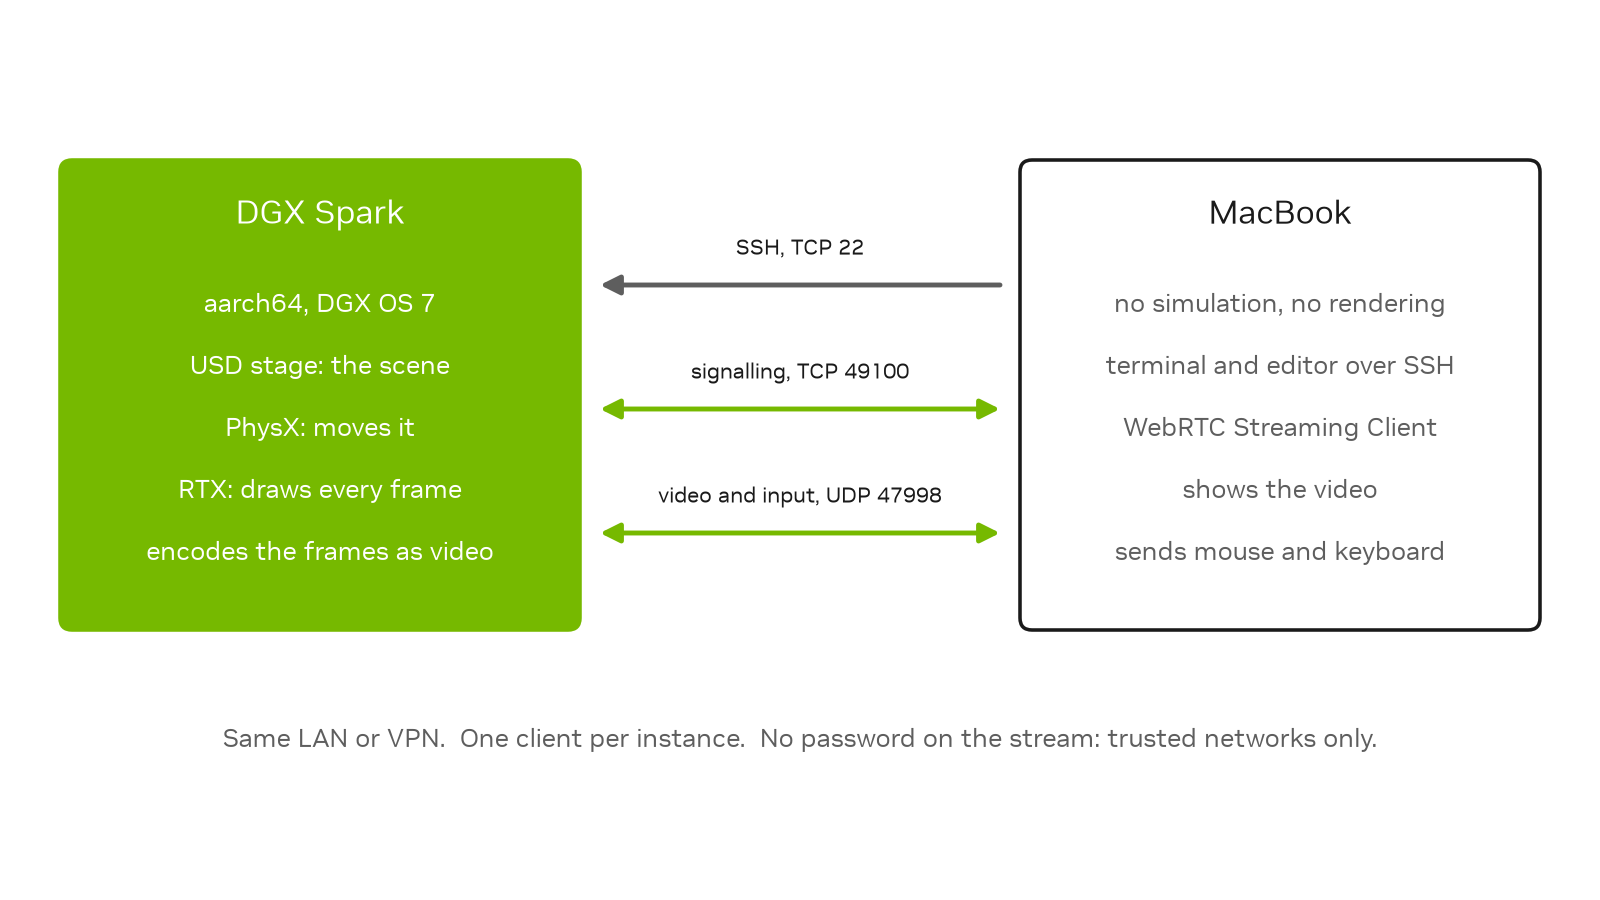

In [ ]:
# HIDE/SHOW
"""Step 4: show a scene to the MacBook over WebRTC, through the
scene's own camera.

Run (env isaac):  python labs/s4_stream.py out/hello_cube.usda
Then connect the Isaac Sim WebRTC Streaming Client on the Mac
to this machine's IP address. Stop with Ctrl-C.
(Adapted from NVIDIA's standalone example livestream.py.)
"""
import os
import sys

import look

look.pick()   # --theme is accepted; the saved scene carries its theme

from isaacsim import SimulationApp

usd = os.path.abspath(sys.argv[1]) if len(sys.argv) > 1 else None
if usd and not os.path.exists(usd):
    sys.exit(f"no such file: {usd}")

CONFIG = {
    "headless": True,          # no window on the Spark itself
    "hide_ui": False,          # but keep the full GUI in the stream
    "width": look.WIDTH, "height": look.HEIGHT,
    "window_width": 1920, "window_height": 1080,
    "renderer": "RealTimePathTracing",
    "display_options": 3286,   # show the default grid
    "open_usd": usd,
}
app = SimulationApp(launch_config=CONFIG)

import isaacsim.core.experimental.utils.stage as stage_utils
from isaacsim.core.experimental.utils.app import enable_extension
from isaacsim.core.rendering_manager import ViewportManager

app.set_setting("/app/window/drawMouse", True)
enable_extension("omni.kit.livestream.app")   # WebRTC server

for _ in range(10):
    app.update()
stage = stage_utils.get_current_stage()
if stage.GetPrimAtPath("/World/Camera"):
    ViewportManager.set_camera("/World/Camera")   # the scene's camera
print("Streaming. Signal port TCP 49100, media port UDP 47998.")

while app.is_running() and not app.is_exiting():
    app.update()                # real-time loop, renders each frame
app.close()

| | DGX Spark | MacBook |
|---|---|---|
| **Role** | simulates and renders every frame | shows the picture, sends mouse and keyboard |
| **Processor** | aarch64, with an NVIDIA GPU | Apple silicon or Intel |
| **Link** | TCP 49100 for signalling, UDP 47998 for video and input | the Isaac Sim WebRTC Streaming Client |
| **Commands** | blocks marked `# Spark` | blocks marked `# Mac` |

Point at a machine, at a line inside it, or at a link to read what it does.

In nine small steps you install Isaac Sim on the Spark, put a cube on its stage, look at it from the MacBook, make it fall, check the fall against the formula, and read what the scene is made of. Every step is a command to type and a result to check. Allow about two hours, most of it waiting for the download.

## Before You Start

| | You need | Details |
|---|---|---|
| **Spark** | a DGX Spark on your network | DGX OS 7. It is the only aarch64 machine that Isaac Sim supports. |
| **Mac** | a MacBook | Apple silicon or Intel. It never simulates or renders. |
| **Network** | both on the same LAN or VPN | The stream uses UDP, which an SSH tunnel cannot carry. |
| **Files** | the folder `ivcl/courses/sim` | The notebooks of this course, with `env/`, `labs/` and `simscene.py` beside them. |

**Where to type.** Each command block says where it is typed. `# Mac` is the Terminal of the MacBook, `# Spark` is a shell on the Spark, and `# Spark (isaac)` is a shell on the Spark with the `isaac` environment active.

**What is folded.** Commands to type are always visible. Longer listings and expected outputs are folded: click a line with a triangle to open it. Above each figure, the script of its step is folded in the same way. All code is shown in the colours that Notion gives it.

**One look for every picture.** The cube is not built inside the scripts. `labs/scene.py` says what is in the scene and `labs/look.py` says how it is drawn: the points, the triangles, the colours (with the shading already in them), the light and the camera. Every script takes `--theme light` (the default) or `--theme dark` for the background; use one theme throughout. This page uses light.

**Two ways to install.** The page IsaacSim101 of this course builds Isaac Sim from source and connects an editor. This page takes the Python package instead, which needs no compiler, and goes on to a first scene. If your Spark already has a build from source, read the last section of this page first.

<aside>

**What was tested, and where the pictures come from.** No Isaac Sim was available while writing this course. The scripts were checked against the Isaac Sim 6.2.0.0 Python source and documentation, and run against real OpenUSD with a stand-in for the simulator. That exercises the script logic and everything written to the stage; it does not exercise the physics engine, the RTX renderer or the stream. So this page tells you what each script should print instead of quoting numbers.

The 3D pictures on this page are *previews*, not Isaac Sim screenshots: each one is the scene of `labs/scene.py`, drawn by the notebook. They are lit in a studio of their own, with soft shadows and pastel colours, so their colours are softer than the colours the scripts write to the stage. Step 4 shows how to make the real picture and compare. What Play shows is computed from the formula of free fall or by a plain loop in NumPy, not by Isaac Sim's physics engine.

</aside>

## Setup

### Reach the Spark from the Mac

1. Create an SSH key if you do not have one, and copy it to the Spark.

    ```bash
    # Mac
    ls ~/.ssh/id_ed25519.pub || ssh-keygen -t ed25519
    ssh-copy-id <user>@<spark-ip>
    ```

2. Give the Spark a short name. Add this to `~/.ssh/config` on the Mac:

    ```text
    Host spark
        HostName <spark-ip>
        User <user>
    ```

3. Test it. You should get a prompt on the Spark without typing a password.

    ```bash
    # Mac
    ssh spark
    ```

### Check the Spark

Run these on the Spark and compare with the comments.

```bash
# Spark
uname -m                      # aarch64
ldd --version | head -1       # GLIBC 2.35 or newer (pip needs it)
nvidia-smi --query-gpu=name,driver_version --format=csv
df -h ~                       # free space in your home folder
```

The Isaac Sim documentation lists driver 580.159.03 on DGX OS 7 as the tested configuration. The packages are large; NVIDIA's DGX Spark playbook asks for 50 GB free for a source build, and the same margin is sensible here.

### Install conda on the Spark

Miniforge is a small conda installer that uses the conda-forge channel and has an aarch64 build.

```bash
# Spark
curl -L -O https://github.com/conda-forge/miniforge/releases/latest/download/Miniforge3-Linux-aarch64.sh
bash Miniforge3-Linux-aarch64.sh -b -p $HOME/miniforge3
$HOME/miniforge3/bin/conda init bash
exec bash
conda --version
```

<aside>

**Checkpoint:** `conda --version` prints a version number and your prompt starts with `(base)`.

</aside>

### Put the Lab Files on the Spark

```bash
# Mac, from the folder that contains ivcl/
ssh spark mkdir -p ivcl/courses/sim
rsync -av ivcl/courses/sim/ spark:ivcl/courses/sim/
```

```bash
# Spark
cd ~/ivcl/courses/sim
ls            # env  labs  simscene.py  and the notebooks
```

Stay in this folder. Every command below is run from here, and every script writes into `out/` next to `labs/`. If your connection is unreliable, start `tmux` first so a dropped connection does not kill a running job.

## The Nine Steps

| | Step | You run | You check |
|---|---|---|---|
| **1** | Create the environment | `conda env create`, then `pip install` twice | the size of what was installed |
| **2** | Check that it works | `pip show isaacsim` | `Version: 6.2.0.0` and `import ok` |
| **3** | Put a cube on the stage | `labs/s3_hello_cube.py` | the prim tree, and `out/hello_cube.usda` |
| **4** | See it from the MacBook | `labs/s4_stream.py`, `labs/s4_shot.py` | the viewport on the Mac, and `out/hello_cube.png` |
| **5** | Make the cube fall | `labs/s5_falling_cube.py` | a final height close to 0.15 m |
| **6** | Check the fall against the formula | `labs/s6_check_fall.py` | the impact time against 0.4163 s |
| **7** | Look inside the stage | `labs/s7_inspect.py` | the schemas before and after physics |
| **8** | Change it while it is running | the streaming client | a red cube that falls on **Play** |
| **9** | Shut down cleanly | `nvidia-smi` | no Python process remains |

### Step 1: Create the Environment

1. Create the environment. The file only prepares Python 3.12 and a recent C++ runtime.

    ```bash
    # Spark
    conda env create -f env/isaac.yml
    conda activate isaac
    ```

    <details>
    <summary>Listing: env/isaac.yml</summary>

    ```yaml
    name: isaac
    channels:
      - conda-forge
    dependencies:
      - python=3.12          # Isaac Sim 6.2 requires Python 3.12
      - pip
      - libstdcxx-ng>=13     # Isaac Sim docs: conda needs CXXABI_1.3.15
    ```

    </details>

2. Install PyTorch and Isaac Sim with pip. These are the commands from the Isaac Sim documentation, with the CUDA 13 build of PyTorch that the Spark needs.

    ```bash
    # Spark (isaac)
    pip install --upgrade pip
    pip install torch==2.11.0 --index-url https://download.pytorch.org/whl/cu130
    pip install "isaacsim[all,extscache]==6.2.0.0" --extra-index-url https://pypi.nvidia.com
    ```

3. Set two variables that apply only inside this environment, then re-activate it.

    ```bash
    # Spark (isaac)
    conda env config vars set \
      OMNI_KIT_ACCEPT_EULA=YES \
      LD_PRELOAD=/lib/aarch64-linux-gnu/libgomp.so.1
    conda deactivate && conda activate isaac
    ```

    `OMNI_KIT_ACCEPT_EULA=YES` means you accept the NVIDIA Omniverse License Agreement. Read it first (link in Sources); if you leave the variable out, Isaac Sim asks you the first time it starts. `LD_PRELOAD` is specific to the Spark: without it some Isaac Sim modules fail to load with a `libgomp` error.

4. Measure what you got, and write the two numbers down.

    ```bash
    # Spark (isaac)
    du -sh $CONDA_PREFIX
    pip list | wc -l
    ```

<aside>

**What to notice.** You installed a renderer, a physics engine, a scene database and several hundred extensions. For scale, a plain Python environment with NumPy and a plotting library is about 0.4 GB.

</aside>

### Step 2: Check That It Works

```bash
# Spark (isaac)
pip show isaacsim | sed -n 1,2p
python -c "import isaacsim; print('import ok')"
```

You should see `Version: 6.2.0.0` and then `import ok`. If Isaac Sim prints an instruction about preloading `libgomp`, the `LD_PRELOAD` variable from Step 1 is not active: run `conda deactivate && conda activate isaac` and try again.

<aside>

**Checkpoint:** both lines print without an error. Do not continue until they do.

</aside>

### Step 3: Put a Cube on the Stage

The scene is a 0.3 m cube whose centre is 1 m above a 3 m square of ground.

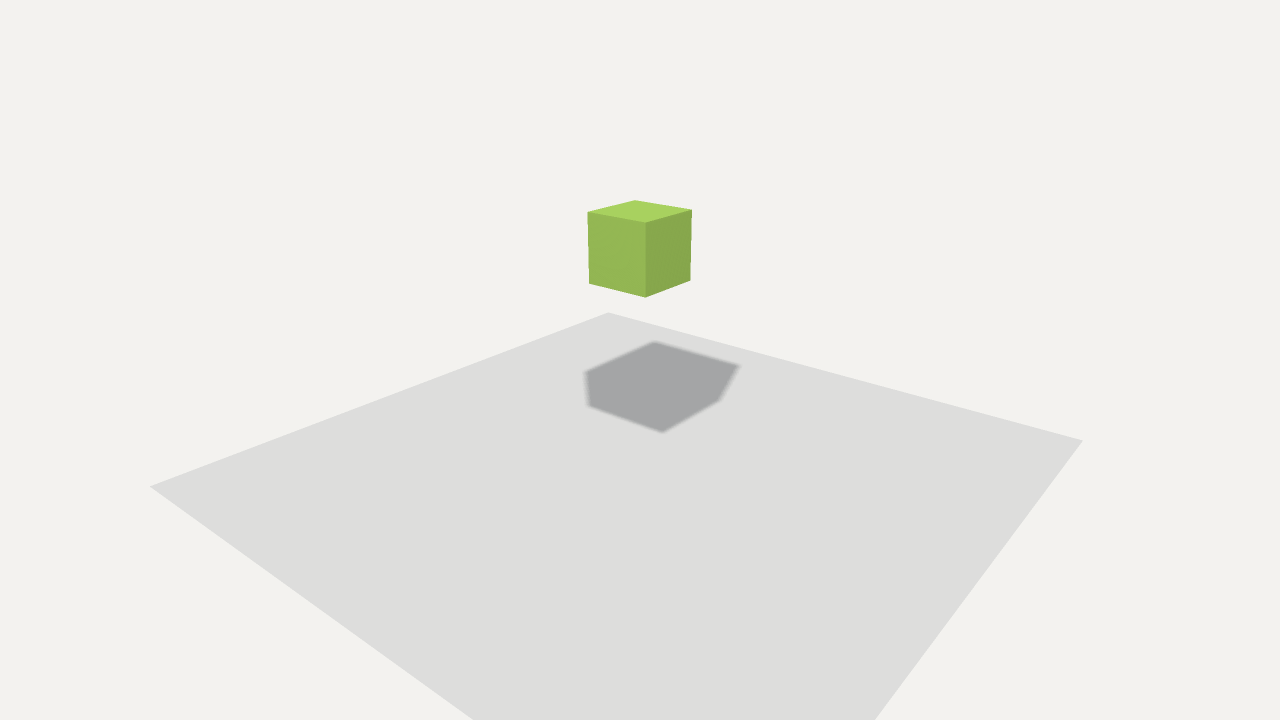

In [ ]:
# HIDE/SHOW
"""Step 3: build the scene on Isaac Sim's stage and save it.

Run (env isaac):  python labs/s3_hello_cube.py
                  python labs/s3_hello_cube.py --theme dark
Output:           out/hello_cube.usda
"""
import os

import look
import scene

THEME = look.pick()              # "light" or "dark"

from isaacsim import SimulationApp

# Start the simulator first. Every other isaacsim / pxr import
# must come after this line.
app = SimulationApp({"headless": True})

import isaacsim.core.experimental.utils.stage as stage_utils

stage_utils.create_new_stage()
stage = stage_utils.get_current_stage()

prims = scene.build()            # ground + cube, from scene.py
look.usd_scene(stage, prims, scene.VIEW, THEME)

os.makedirs("out", exist_ok=True)
path = os.path.abspath("out/hello_cube.usda")
stage_utils.save_stage(path)
print(stage_utils.generate_stage_representation(mode="tree"))
print("wrote", path)
app.close()

| | In the picture | On the stage |
|---|---|---|
| **Cube** | green, edge 0.3 m, centre 1 m above the ground | `/World/Look/cube`, a mesh of 8 points and 12 triangles |
| **Ground** | grey, 3 m on a side, at height $z = 0$ | `/World/Look/ground`, a mesh of 4 points and 2 triangles |
| **Camera** | the view of this picture, $45^\circ$ high | `/World/Camera` |
| **Light** | a soft lamp and light from the sky, in this preview only | `/World/Dome`, an even light from all sides |

The picture is a preview of `out/hello_cube.usda`, the scene this step saves. Step 4 makes the real picture.

1. Read the scene. It is the whole of `labs/scene.py`.

    <details>
    <summary>Listing: labs/scene.py</summary>

    ```python
    import look

    SIZE = 0.3                      # cube edge, metres
    START = (0.0, 0.0, 1.0)         # cube centre at the start, metres
    VIEW = look.View(eye=(2.2, -2.7, 1.9), target=(0.0, 0.0, 0.5))


    def build(centre=START):
        """A 3 m square of ground and a green cube above it."""
        return [look.ground(half=1.5),
                look.box("cube", centre, SIZE, look.GREEN_RGB)]
    ```

    </details>

    `look.box()` turns "a box of this size here" into 8 points and 12 triangles and gives each triangle its shaded colour. `look.View` is the camera: where the eye is and what it looks at, in metres.

2. Read the script. An Isaac Sim script always starts the application first and imports the rest afterwards. Then it makes an empty stage and writes the scene onto it.

    <details>
    <summary>Listing: labs/s3_hello_cube.py, the two parts that matter</summary>

    ```python
    from isaacsim import SimulationApp

    # Start the simulator first. Every other isaacsim / pxr import
    # must come after this line.
    app = SimulationApp({"headless": True})
    ```

    ```python
    import isaacsim.core.experimental.utils.stage as stage_utils

    stage_utils.create_new_stage()
    stage = stage_utils.get_current_stage()

    prims = scene.build()            # ground + cube, from scene.py
    look.usd_scene(stage, prims, scene.VIEW, THEME)
    ```

    </details>

3. Run it.

    ```bash
    # Spark (isaac)
    python labs/s3_hello_cube.py
    ```

    The first start takes several minutes while Isaac Sim caches extensions and shaders. The script prints the stage as a tree: under `World` you should find `Look` with `ground`, `cube` and a `Matte` material, then `Camera` and `Dome`. The last line is `wrote` followed by the path of `out/hello_cube.usda`.

4. Open the file it saved. It is text.

    ```bash
    # Spark
    grep -n "def " out/hello_cube.usda
    less out/hello_cube.usda
    ```

    Find `def Mesh "cube"` and, under it, `points` (8 of them) and `faceVertexIndices` (12 triangles).

<aside>

**What to notice.** The script's output is not a picture. It is a *stage*: a tree of typed *prims* with attributes. The camera and the light are prims in the same tree as the cube.

</aside>

**How the look is fixed.** Four things are decided in `labs/look.py`, not by the renderer. Open the file and find each function; each is a few lines.

| | Where | How |
|---|---|---|
| **Camera** | `usd_camera()` | A USD camera at `View.eye` looking at `View.target`. The vertical field of view is $45^\circ$ and the picture is 1280 by 720 pixels. |
| **Coordinates** | `usd_mesh()` | Metres, with Z up and the ground at height $z = 0$ in every scene. |
| **Colour** | `linear()` | Colours are defined as screen colours. USD stores colours in linear light, so they are converted on the way in. |
| **Shading** | `shade()` | The brightness of every face is computed from one light direction and stored in the face's colour. The material is matte and the light is an even dome, so the renderer should add nothing. |

The same rules as formulas. A face with unit normal $\mathbf{n}$ and colour $\mathbf{c}$ is stored in the colour

$$
\mathbf{c}_{\text{shaded}} = \mathbf{c}\,\bigl(0.45 + 0.55\,\max(0,\ \mathbf{n}\cdot\boldsymbol{\ell})\bigr)
$$

where $\boldsymbol{\ell}$ is the unit vector towards the light. Each screen colour value $c$ between 0 and 1 is converted to linear light for USD:

$$
c_{\text{linear}} =
\begin{cases}
c / 12.92 & \text{if } c \le 0.04045 \\
\bigl((c + 0.055) / 1.055\bigr)^{2.4} & \text{otherwise}
\end{cases}
$$

The focal length $f$ of the camera follows from the field of view $\theta = 45^\circ$ and the vertical aperture $h = 20.25$ mm:

$$
f = \frac{h}{2\tan(\theta / 2)} = \frac{20.25}{2\tan 22.5^\circ} = 24.44\ \text{mm}
$$

### Step 4: See It from the MacBook

**Part A: stream the live application.**

1. Find the Spark's address, then start a streaming session that opens your scene.

    ```bash
    # Spark (isaac)
    hostname -I | awk '{print $1}'
    python labs/s4_stream.py out/hello_cube.usda
    ```

    The script is NVIDIA's `livestream.py` example plus two things: it opens your file, and it looks through the scene's camera.

    <details>
    <summary>Listing: labs/s4_stream.py, the configuration and the stream</summary>

    ```python
    CONFIG = {
        "headless": True,          # no window on the Spark itself
        "hide_ui": False,          # but keep the full GUI in the stream
        "width": look.WIDTH, "height": look.HEIGHT,
        "window_width": 1920, "window_height": 1080,
        "renderer": "RealTimePathTracing",
        "display_options": 3286,   # show the default grid
        "open_usd": usd,
    }
    app = SimulationApp(launch_config=CONFIG)
    ```

    ```python
    enable_extension("omni.kit.livestream.app")   # WebRTC server

    for _ in range(10):
        app.update()
    stage = stage_utils.get_current_stage()
    if stage.GetPrimAtPath("/World/Camera"):
        ViewportManager.set_camera("/World/Camera")   # the scene's camera
    print("Streaming. Signal port TCP 49100, media port UDP 47998.")
    ```

    </details>

2. Wait until the script prints `Streaming.` and the log stops scrolling. In a second Spark terminal, confirm that both ports are open.

    ```bash
    # Spark, second terminal
    ss -ltn | grep 49100     # TCP, signalling
    ss -lun | grep 47998     # UDP, video
    ```

3. On the Mac, download the **Isaac Sim WebRTC Streaming Client** for macOS from the *Latest Release* section of the Isaac Sim download page, open it, type the Spark's address in place of `127.0.0.1`, and click **Connect**.

4. The full Isaac Sim interface appears with your cube in the viewport, seen from the scene's camera. Hold Alt and drag to orbit.

5. **Experiment.** Press Ctrl-C in the first Spark terminal. The picture on the Mac stops. Start the script again and reconnect.

**Part B: save one frame as a file.**

6. Stop the stream (Ctrl-C), then capture what the scene's camera sees.

    ```bash
    # Spark (isaac)
    python labs/s4_shot.py out/hello_cube.usda out/hello_cube.png
    ```

    The script attaches an RTX camera sensor to `/World/Camera`, waits for the renderer to settle and saves 1280 by 720 pixels. If Pillow is not installed in the environment, it saves the pixels as `out/hello_cube.png.npy` instead; `pip install pillow` fixes that.

7. Copy the picture to the Mac and compare it with the preview in Step 3.

    ```bash
    # Mac
    scp spark:ivcl/courses/sim/out/hello_cube.png .
    open hello_cube.png
    ```

    The cube and the ground should sit where they do in the preview. The colours will differ: the preview is lit in a studio of its own, with a soft lamp, shadows and pastel colours, while your capture shows the plain colours of `labs/look.py` under an even light. If your picture is too bright or too dark, change `DOME_INTENSITY` in `labs/look.py` and run Step 3 and step 6 again. If its colours are more contrasty than the colours in `labs/look.py`, the renderer is applying a film-like tone curve: in the streamed window open **Render Settings > Post Processing > Tone Mapping** and choose a linear operator. These two adjustments could not be tested while writing this page.

<aside>

**What to notice.** Isaac Sim draws every frame on the Spark's GPU and sends *video*; the Mac is a screen and a mouse. That is why stopping the script stops the picture, why the stream needs UDP and so cannot go through an SSH tunnel, why only one client can be connected to an instance, and why the documentation tells you to keep the stream on a trusted network: it has no password and no encryption.

</aside>

### Step 5: Make the Cube Fall

You do not program the fall. You say which prim is a rigid body and which prims collide, and step the physics engine.

1. Read the four lines that declare the physics, and the loop. `SimulationManager.step()` advances the physics by one time step without rendering.

    <details>
    <summary>Listing: labs/s5_falling_cube.py, the declaration and the loop</summary>

    ```python
    paths = look.usd_scene(stage, scene.build(), scene.VIEW, THEME)

    # Physics is declared, not programmed:
    body = RigidPrim(paths["cube"])                     # mass, gravity
    shape = GeomPrim(paths["cube"], apply_collision_apis=True)
    shape.set_collision_approximations("convexHull")    # cube collides
    GeomPrim(paths["ground"], apply_collision_apis=True)  # ground too
    ```

    ```python
    SimulationManager.set_physics_dt(DT)   # set before pressing play
    app_utils.play()
    app.update()
    ```

    ```python
    for _ in range(STEPS):
        SimulationManager.step()           # one physics step, no render
        pos, _ = body.get_world_poses()
        rows.append((SimulationManager.get_simulation_time(),
                     float(pos.numpy()[0, 2])))
    ```

    </details>

2. Run it.

    ```bash
    # Spark (isaac)
    python labs/s5_falling_cube.py
    ```

    The script prints the number of steps and the time step it measured (it should be $1/60 = 0.0167$ s), then the first and the final height of the cube. The final height should be close to 0.15 m: the cube resting on the ground. It writes `out/fall.csv` and `out/falling_cube.usda`.

3. Watch it. Stream the saved scene and press **Play** in the toolbar on the left.

    ```bash
    # Spark (isaac)
    python labs/s4_stream.py out/falling_cube.usda
    ```

The fall as the formula of Step 6 gives it. Press Play:

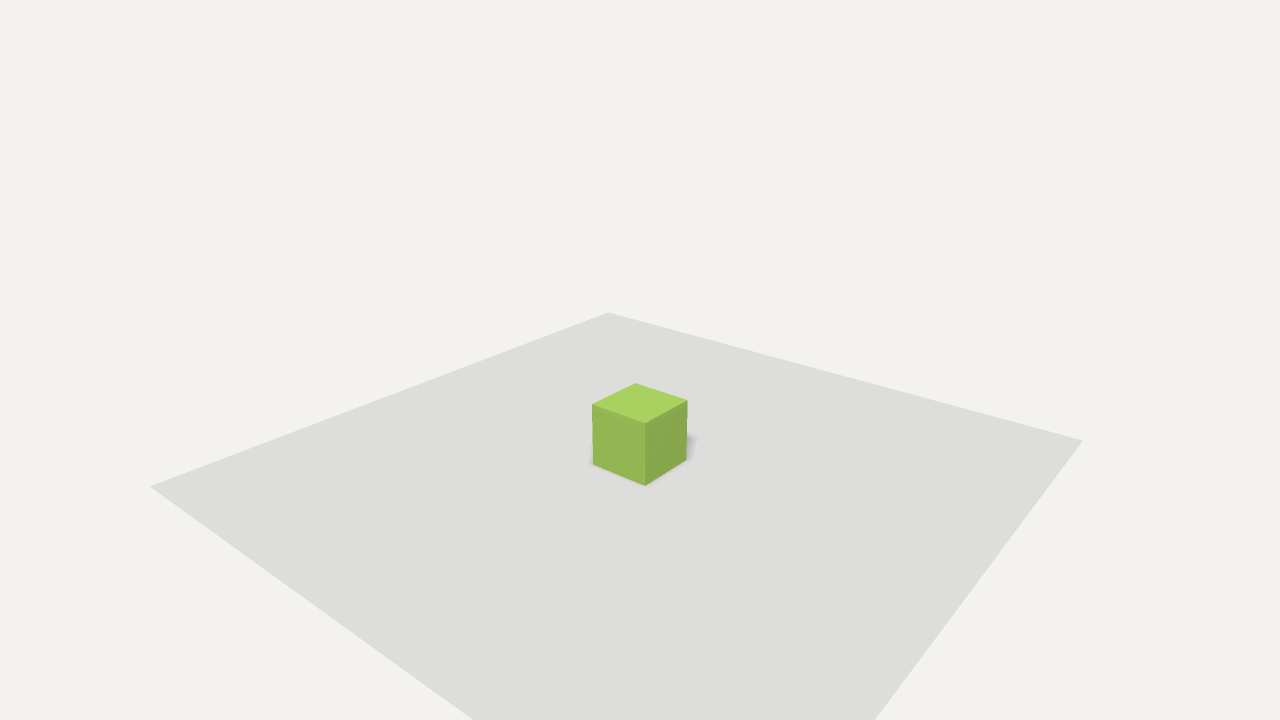

In [ ]:
# HIDE/SHOW
"""Step 5: make the cube fall. You only declare what is a rigid
body and what collides; the physics engine does the rest.

Run (env isaac):  python labs/s5_falling_cube.py
Output:           out/fall.csv, out/falling_cube.usda
"""
import os

import look
import scene

THEME = look.pick()

from isaacsim import SimulationApp

app = SimulationApp({"headless": True})

import numpy as np
import isaacsim.core.experimental.utils.app as app_utils
import isaacsim.core.experimental.utils.stage as stage_utils
from isaacsim.core.experimental.prims import GeomPrim, RigidPrim
from isaacsim.core.simulation_manager import SimulationManager

DT = 1 / 60     # physics time step, s
STEPS = 120     # 2 simulated seconds

stage_utils.create_new_stage()
stage = stage_utils.get_current_stage()
paths = look.usd_scene(stage, scene.build(), scene.VIEW, THEME)

# Physics is declared, not programmed:
body = RigidPrim(paths["cube"])                     # mass, gravity
shape = GeomPrim(paths["cube"], apply_collision_apis=True)
shape.set_collision_approximations("convexHull")    # cube collides
GeomPrim(paths["ground"], apply_collision_apis=True)  # ground too

os.makedirs("out", exist_ok=True)
stage_utils.save_stage(os.path.abspath("out/falling_cube.usda"))

SimulationManager.set_physics_dt(DT)   # set before pressing play
app_utils.play()
app.update()

pos, _ = body.get_world_poses()
rows = [(SimulationManager.get_simulation_time(),
         float(pos.numpy()[0, 2]))]
for _ in range(STEPS):
    SimulationManager.step()           # one physics step, no render
    pos, _ = body.get_world_poses()
    rows.append((SimulationManager.get_simulation_time(),
                 float(pos.numpy()[0, 2])))
rows = np.array(rows)
rows[:, 0] -= rows[0, 0]               # start the clock at zero

np.savetxt("out/fall.csv", rows, delimiter=",", header="t,z",
           comments="")
print(f"steps={STEPS} dt={np.diff(rows[:, 0]).mean():.4f}s")
print(f"first z={rows[0, 1]:.3f} m  final z={rows[-1, 1]:.3f} m"
      f"  (half the cube = {scene.SIZE/2})")
print("wrote out/fall.csv, out/falling_cube.usda")
app_utils.stop()
app.close()

| | Value | Where it comes from |
|---|---|---|
| **Start** | centre at $z_0 = 1$ m | `START` in `labs/scene.py` |
| **End** | centre at $s/2 = 0.15$ m | half the edge $s = 0.3$ m above the ground |
| **Time step** | $\Delta t = 1/60$ s | `SimulationManager.set_physics_dt(DT)` |
| **Duration** | 120 steps, 2 s | `STEPS` in the script |
| **In the picture** | 0.6 s of free fall, from the formula | `FallingCube.motion()` in `simscene.py` |

<aside>

**What to notice.** Four lines declared a body and two colliders. They would work unchanged for a tumbling cube, a stack of cubes or a robot. Without a physics engine the same step means writing the integrator and the ground test yourself, and writing them again for every new shape.

</aside>

### Step 6: Check the Fall Against the Formula

Without air, a cube with edge $s$ that is dropped from height $z_0$ falls freely until its centre is half an edge above the ground:

$$
z(t) = \max\!\Bigl(z_0 - \tfrac{1}{2}\,g\,t^2,\ \tfrac{s}{2}\Bigr),
\qquad
t_{\text{impact}} = \sqrt{\frac{2\,(z_0 - s/2)}{g}}
$$

With $z_0 = 1$ m, $s = 0.3$ m and $g = 9.81\ \text{m/s}^2$ the impact time is $t_{\text{impact}} = 0.4163$ s.

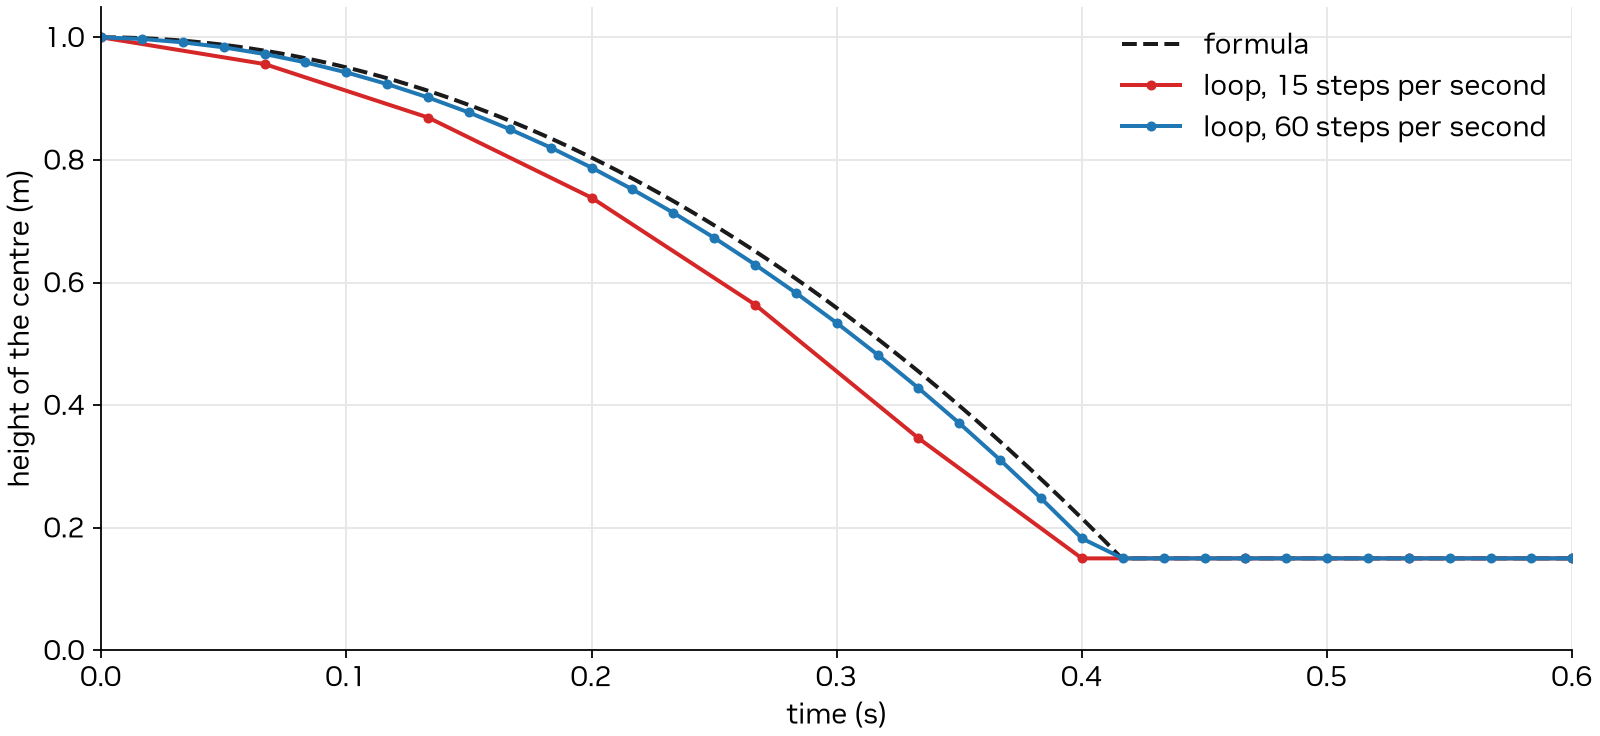

In [ ]:
# HIDE/SHOW
"""Step 6: check the simulated fall against the formula. Plain
NumPy; the simulator is not started.

Run (env isaac):  python labs/s6_check_fall.py
Needs:            out/fall.csv  (from Step 5)
"""
import os
import sys

import numpy as np

import scene

G, Z0, HALF = 9.81, scene.START[2], scene.SIZE / 2

if not os.path.exists("out/fall.csv"):
    sys.exit("missing out/fall.csv: run labs/s5_falling_cube.py first")
rows = np.loadtxt("out/fall.csv", delimiter=",", skiprows=1)
t, z = rows[:, 0], rows[:, 1]

exact = np.maximum(Z0 - 0.5 * G * t**2, HALF)
t_exact = np.sqrt(2 * (Z0 - HALF) / G)
landed = t[z <= HALF + 1e-3]             # within 1 mm of rest
falling = t < t_exact - 0.02             # samples before impact
dts = np.diff(t)

print(f"samples                 {len(t)}")
print(f"time step               mean {dts.mean():.5f} s,"
      f" min {dts.min():.5f}, max {dts.max():.5f}")
print(f"impact, formula         {t_exact:.4f} s")
print("impact, simulation      "
      + (f"{landed[0]:.4f} s" if len(landed) else "never landed"))
print(f"largest gap to formula  "
      f"{np.abs(z - exact)[falling].max() * 100:.2f} cm while falling")
print(f"rest height             {z[-1]:.4f} m"
      f" (half the cube = {HALF})")

| | Curve | Height of the centre while falling |
|---|---|---|
| **Formula** | dashed | $z_0 - \tfrac{1}{2}\,g\,t^2$ |
| **Loop, 60 steps per second** | blue | below the formula by $\tfrac{1}{2}\,g\,t\,\Delta t$ with $\Delta t = 1/60$ s, about 3 cm just before impact |
| **Loop, 15 steps per second** | red | the same gap with $\Delta t = 1/15$ s, four times as large |
| **Circles** | one on each curve | where each cube is at the time of the slider |

Point at a step of a loop to read its time, its height and its gap to the formula. The two loops in the chart are a stand-in written in NumPy, not Isaac Sim's physics engine. They show what a first-order integrator does. The steps below find out what your simulation did.

1. Read the check. It is plain NumPy and does not start the simulator.

    <details>
    <summary>Listing: labs/s6_check_fall.py, the comparison</summary>

    ```python
    exact = np.maximum(Z0 - 0.5 * G * t**2, HALF)
    t_exact = np.sqrt(2 * (Z0 - HALF) / G)
    landed = t[z <= HALF + 1e-3]             # within 1 mm of rest
    falling = t < t_exact - 0.02             # samples before impact
    dts = np.diff(t)
    ```

    </details>

2. Run it.

    ```bash
    # Spark (isaac)
    python labs/s6_check_fall.py
    ```

    It prints six lines: the number of samples; the mean, smallest and largest time step in the file; the impact time from the formula, which is 0.4163 s; the impact time in your simulation; the largest gap between simulation and formula while the cube is still falling; and the rest height.

3. Answer these from your own output.

    - Is the mean time step exactly $\Delta t = 1/60$ s? Are the smallest and the largest the same?
    - Is the largest gap closer to a millimetre or to several centimetres? Compare it with the blue curve of the chart. What does your number suggest about the engine's integrator?
    - Does the cube come to rest at exactly 0.150 m? What could account for a small difference?

### Step 7: Look Inside the Stage

```bash
# Spark (isaac)
python labs/s7_inspect.py
```

The script opens `out/hello_cube.usda` and prints, in this order:

1. the prim tree;
2. the type of `/World/Look/cube`, which is `Mesh`;
3. the schemas applied to the cube before any physics;
4. every attribute on the cube: `points`, `faceVertexCounts`, `faceVertexIndices`, the display colour, the transform that places it;
5. the schemas applied after `RigidPrim(...)` and `GeomPrim(..., apply_collision_apis=True)`: the list has grown by rigid-body and collision schemas;
6. whether any attribute now mentions physics: `True`.

<details>
<summary>Listing: labs/s7_inspect.py, where physics is added</summary>

```python
# Physics is extra data attached to the same prim.
RigidPrim("/World/Look/cube")
GeomPrim("/World/Look/cube", apply_collision_apis=True)
print("applied schemas after: ", list(cube.GetAppliedSchemas()))
```

</details>

<aside>

**What to notice.** Physics is not a separate system with its own copy of the scene. It is more attributes on the same prim. That is what lets a physics engine, a renderer and a sensor model share one stage.

</aside>

### Step 8: Change It While It Is Running

1. Change the scene: in `labs/scene.py` replace `look.GREEN_RGB` with `(0.86, 0.08, 0.24)`. Run Step 3 again, then stream the new file.

    ```bash
    # Spark (isaac)
    python labs/s3_hello_cube.py
    python labs/s4_stream.py out/hello_cube.usda
    ```

2. Connect the client on the Mac. The cube is red.
3. In the **Stage** panel on the right, open `World > Look` and click `cube`.
4. Press **W** and drag an arrow to move the cube. Press **E** to rotate it, **R** to scale it.
5. In the **Property** panel, click **Add > Physics > Rigid Body with Colliders Preset**. Do the same for `ground`, choosing **Colliders Preset**.
6. Press **Play** on the left toolbar. The cube falls from where you put it. Press **Stop** and it returns to where you left it.
7. Put `look.GREEN_RGB` back in `labs/scene.py`.

The scene after the first of these steps:

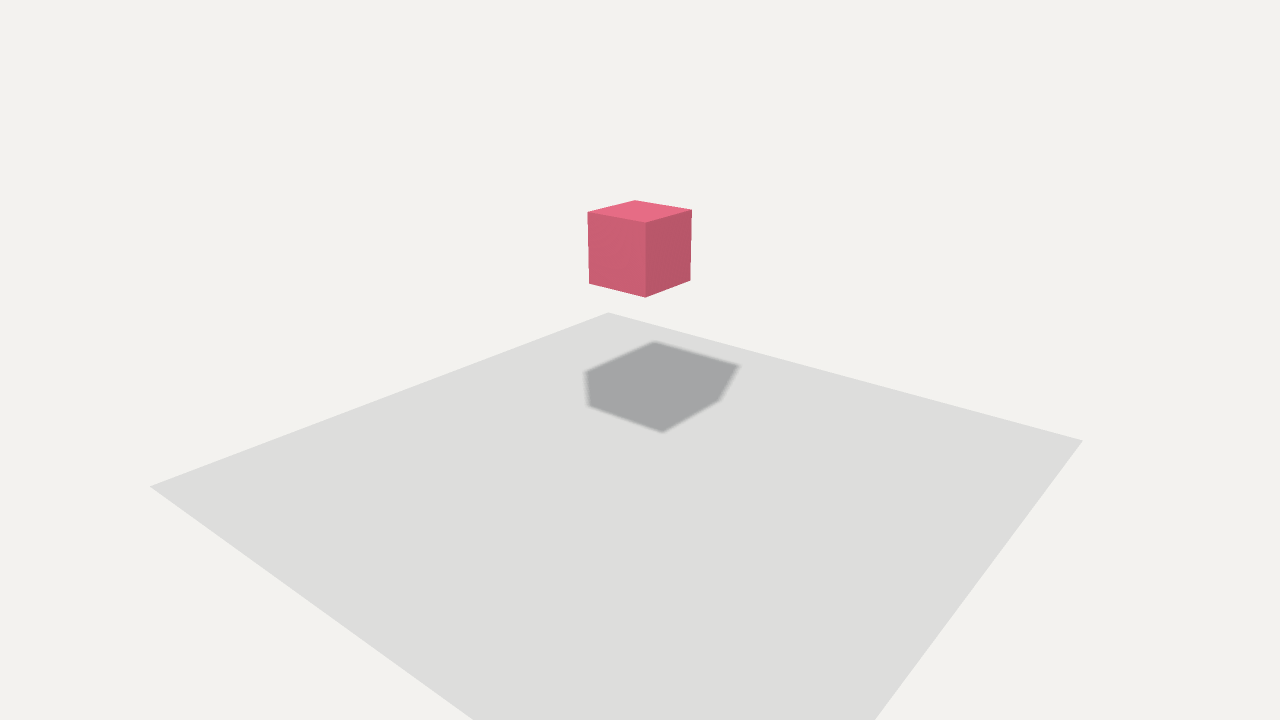

In [ ]:
# HIDE/SHOW
"""Step 3: build the scene on Isaac Sim's stage and save it.

Run (env isaac):  python labs/s3_hello_cube.py
                  python labs/s3_hello_cube.py --theme dark
Output:           out/hello_cube.usda
"""
import os

import look
import scene

THEME = look.pick()              # "light" or "dark"

from isaacsim import SimulationApp

# Start the simulator first. Every other isaacsim / pxr import
# must come after this line.
app = SimulationApp({"headless": True})

import isaacsim.core.experimental.utils.stage as stage_utils

stage_utils.create_new_stage()
stage = stage_utils.get_current_stage()

prims = scene.build()            # ground + cube, from scene.py
look.usd_scene(stage, prims, scene.VIEW, THEME)

os.makedirs("out", exist_ok=True)
path = os.path.abspath("out/hello_cube.usda")
stage_utils.save_stage(path)
print(stage_utils.generate_stage_representation(mode="tree"))
print("wrote", path)
app.close()

| | Before | After |
|---|---|---|
| **Line in** `labs/scene.py` | `look.GREEN_RGB` | `(0.86, 0.08, 0.24)` |
| **Points and triangles** | 8 and 12 | unchanged |
| **Colour of each face** | green, with its shading | red, with the same shading |

<aside>

**What to notice.** The scene is live. You edited a running simulator, and Stop restored the state from before Play.

</aside>

### Step 9: Shut Down Cleanly

In the streamed window choose **File > Exit**, then close the client on the Mac. If the script is still running, press Ctrl-C in its terminal.

```bash
# Spark
conda deactivate
nvidia-smi        # no python process should remain
```

## What You Just Saw

| | Answer for Isaac Sim |
|---|---|
| **Where is the picture drawn?** | On the Spark's GPU |
| **What travels over the network?** | Video, every frame; your input, back |
| **Does an SSH tunnel work?** | No: the video is UDP |
| **How many viewers?** | One client per instance |
| **Who computes motion?** | The physics engine |
| **What is a scene?** | A USD stage: prims and attributes |
| **What does a cube know?** | Its points and triangles, and after Step 5 its mass, velocity and collision shape |
| **Where does the scene come from?** | `labs/scene.py`, written to the stage by `labs/look.py` |
| **What does it cost?** | Your two numbers from Step 1 |
| **Best for** | Anything that moves, collides or is sensed |

## Troubleshooting

| | What to do |
|---|---|
| `conda: command not found` | Run `exec bash` after `conda init bash`, or open a new terminal. |
| **pip cannot find** `isaacsim` | Check that `python --version` is 3.12 and that `--extra-index-url https://pypi.nvidia.com` is on the command. |
| **Error mentioning** `libgomp.so.1` | The `LD_PRELOAD` variable is missing. Repeat the `conda env config vars set` command from Step 1 and re-activate. |
| **Error mentioning** `CXXABI_1.3.15` | The C++ runtime is too old. Run `conda install -c conda-forge "libstdcxx-ng>=13"` in the `isaac` environment. |
| **Asked to accept a licence at every start** | `OMNI_KIT_ACCEPT_EULA` is not set in this environment. |
| **A script stops at an import** | Module names under `isaacsim.core.experimental` belong to Isaac Sim 6.x. Check that `pip show isaacsim` reports 6.2.0.0. |
| **Client cannot connect** | Check both ports with `ss` as in Step 4. A firewall must allow TCP 49100 *and* UDP 47998. Only one client can be connected at a time. |
| **Client shows a black window** | Isaac Sim is still loading. Wait a minute and reconnect. |
| **The picture is too bright or too dark** | Change `DOME_INTENSITY` in `labs/look.py` and run the script again. |
| **The cube falls through the ground** | The ground needs a collider too: check the line `GeomPrim(paths["ground"], apply_collision_apis=True)` in `labs/s5_falling_cube.py`. |

## Checklist

You are ready for the next page, Overview of Visualization, when you can tick every line.

- [ ] `conda env list` on the Spark shows `isaac`, and `pip show isaacsim` reports 6.2.0.0.
- [ ] `out/` contains `hello_cube.usda`, `hello_cube.png`, `falling_cube.usda` and `fall.csv`.
- [ ] You have seen the Isaac Sim viewport on the Mac and made the cube fall with **Play**.
- [ ] Your `hello_cube.png` shows the same view as the preview in Step 3.
- [ ] You can say what `labs/s6_check_fall.py` reported for the impact time and the rest height.
- [ ] You can say, in one sentence, where the pixels are drawn and what travels over the network.

## If You Built Isaac Sim from Source

NVIDIA's DGX Spark playbook builds Isaac Sim from the GitHub repository instead of installing it with pip, and so does the page IsaacSim101. If your Spark was set up that way, everything above still applies with one change: run scripts with the build's own Python instead of the `isaac` environment's.

```bash
# Spark
export ISAACSIM_PATH=$HOME/IsaacSim/_build/linux-aarch64/release
export LD_PRELOAD="$LD_PRELOAD:/lib/aarch64-linux-gnu/libgomp.so.1"
$ISAACSIM_PATH/python.sh labs/s3_hello_cube.py
```

The source build needs GCC/G++ 11, Git LFS and about 50 GB of disk; the playbook in Sources has the full steps. The Isaac Sim documentation also describes a browser-based viewer, deployed with Docker Compose on the Spark, as an alternative to the native streaming client.

## Sources

- [Isaac Sim: Python environment installation (pip, conda)](https://docs.isaacsim.omniverse.nvidia.com/latest/installation/install_python.html)
- [Isaac Sim: requirements, including DGX Spark](https://docs.isaacsim.omniverse.nvidia.com/latest/installation/requirements.html)
- [Isaac Sim: livestream clients](https://docs.isaacsim.omniverse.nvidia.com/latest/installation/manual_livestream_clients.html)
- [Isaac Sim: download page (WebRTC Streaming Client)](https://docs.isaacsim.omniverse.nvidia.com/latest/installation/download.html)
- [Isaac Sim: basic usage tutorial](https://docs.isaacsim.omniverse.nvidia.com/latest/introduction/quickstart_isaacsim.html)
- [Isaac Sim: licences](https://docs.isaacsim.omniverse.nvidia.com/latest/common/licenses.html)
- [Isaac Sim standalone examples: getting_started.py and livestream.py](https://github.com/isaac-sim/IsaacSim)
- [NVIDIA DGX Spark playbook: Isaac Sim and Isaac Lab](https://github.com/NVIDIA/dgx-spark-playbooks/blob/main/nvidia/isaac/README.md)
- [Miniforge](https://github.com/conda-forge/miniforge)